# Project Title:
### PRCP-1028-Skin-Disorder-Prediction

# Objective

- To analyze clinical and histopathological data related to skin diseases.
- To preprocess and prepare the dataset for machine learning models.
- To build and evaluate multiple machine learning models for skin disease prediction.
- To identify the best-performing model based on evaluation metrics.
- To provide insights that support early diagnosis of skin diseases.

# Import Libraries 

In [1]:
import numpy as np 
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt 
%matplotlib inline 
import warnings
warnings.filterwarnings('ignore')





# Load Dataset 

In [2]:
data = pd.read_csv("dataset_35_dermatology (1).csv")
data

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
361,2,1,1,0,1,0,0,0,0,0,...,0,0,1,0,0,0,2,0,25,4
362,3,2,1,0,1,0,0,0,0,0,...,1,0,1,0,0,0,2,0,36,4
363,3,2,2,2,3,2,0,2,0,0,...,0,3,0,3,0,0,2,3,28,3
364,2,1,3,1,2,3,0,2,0,0,...,0,2,0,1,0,0,2,3,50,3


# Basic Checks 

In [3]:
data.head()

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45,3


In [4]:
data.tail()

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
361,2,1,1,0,1,0,0,0,0,0,...,0,0,1,0,0,0,2,0,25,4
362,3,2,1,0,1,0,0,0,0,0,...,1,0,1,0,0,0,2,0,36,4
363,3,2,2,2,3,2,0,2,0,0,...,0,3,0,3,0,0,2,3,28,3
364,2,1,3,1,2,3,0,2,0,0,...,0,2,0,1,0,0,2,3,50,3
365,3,2,2,0,0,0,0,0,3,3,...,2,0,0,0,0,0,3,0,35,1


In [5]:
data.shape

(366, 35)

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 35 columns):
 #   Column                                    Non-Null Count  Dtype 
---  ------                                    --------------  ----- 
 0   erythema                                  366 non-null    int64 
 1   scaling                                   366 non-null    int64 
 2   definite_borders                          366 non-null    int64 
 3   itching                                   366 non-null    int64 
 4   koebner_phenomenon                        366 non-null    int64 
 5   polygonal_papules                         366 non-null    int64 
 6   follicular_papules                        366 non-null    int64 
 7   oral_mucosal_involvement                  366 non-null    int64 
 8   knee_and_elbow_involvement                366 non-null    int64 
 9   scalp_involvement                         366 non-null    int64 
 10  family_history                            366 non-

In [7]:
#The dataset contains rows representing patient records and columns representing clinical, histopathological features along with age and disease class.

In [8]:
data['class'].value_counts()

class
1    112
3     72
2     61
5     52
4     49
6     20
Name: count, dtype: int64

In [9]:
#The class distribution shows that Class 1 has the highest number of samples,while Class 6 has the least.

# Domain Analysis 

Domain : Healthcare

## Skin Diseases Covered in the Dataset

1. **Psoriasis**  
   A chronic autoimmune skin disease characterized by red, scaly patches,
   commonly affecting the scalp, elbows, and knees.

2. **Seborrheic Dermatitis**  
   A common inflammatory condition causing flaky scales and redness,
   mainly affecting oily areas such as the scalp and face.

3. **Lichen Planus**  
   An inflammatory skin disorder presenting as purple, itchy, flat-topped
   papules, often involving oral mucosa.

4. **Pityriasis Rosea**  
   A self-limiting skin condition marked by oval, scaly patches,
   usually affecting young adults.

5. **Chronic Dermatitis**  
   A long-term inflammatory skin condition causing persistent itching,
   redness, and skin thickening.

6. **Pityriasis Rubra Pilaris**  
   A rare skin disorder characterized by reddish-orange scaling patches
   and thickened skin, often difficult to diagnose.


The dataset includes both clinical and histopathological features. Clinical features
represent visible symptoms observed during physical examination, while
histopathological features are obtained through microscopic examination of skin
biopsy samples. Combining both feature types improves diagnostic accuracy.


# EDA

In [10]:
data.describe()

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,focal_hypergranulosis,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,class
count,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,...,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000
mean,2.068306,1.795082,1.549180,1.366120,0.633880,0.448087,0.166667,0.377049,0.614754,0.519126,...,0.393443,0.464481,0.456284,0.953552,0.453552,0.103825,0.114754,1.866120,0.554645,2.803279
std,0.664753,0.701527,0.907525,1.138299,0.908016,0.957327,0.570588,0.834147,0.982979,0.905639,...,0.849406,0.864899,0.954873,1.130172,0.954744,0.450433,0.488723,0.726108,1.105908,1.597803
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000
50%,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,3.000000
75%,2.000000,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,...,0.000000,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,2.000000,0.000000,4.000000
max,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,...,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,6.000000


In [11]:
#The dataset contains 366 patient records with 34 attributes, including clinical,histopathological features, age, and the target class.
#The target variable (class) ranges from 1 to 6, confirming the presence of six different skin disease categories.
#Most clinical and histopathological features have values ranging from 0 to 3, confirming ordinal encoding of symptom severity.

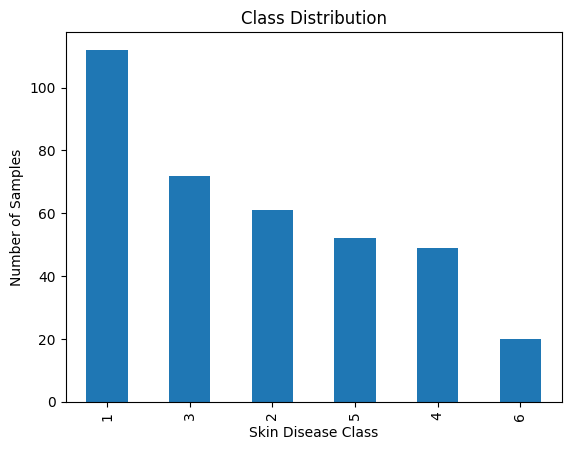

In [12]:
plt.figure()
data['class'].value_counts().plot(kind='bar')
plt.title('Class Distribution')
plt.xlabel('Skin Disease Class')
plt.ylabel('Number of Samples')
plt.show()

In [13]:
#Class 1 has the highest samples, while Class 6 has the lowest, indicating slight class imbalance.

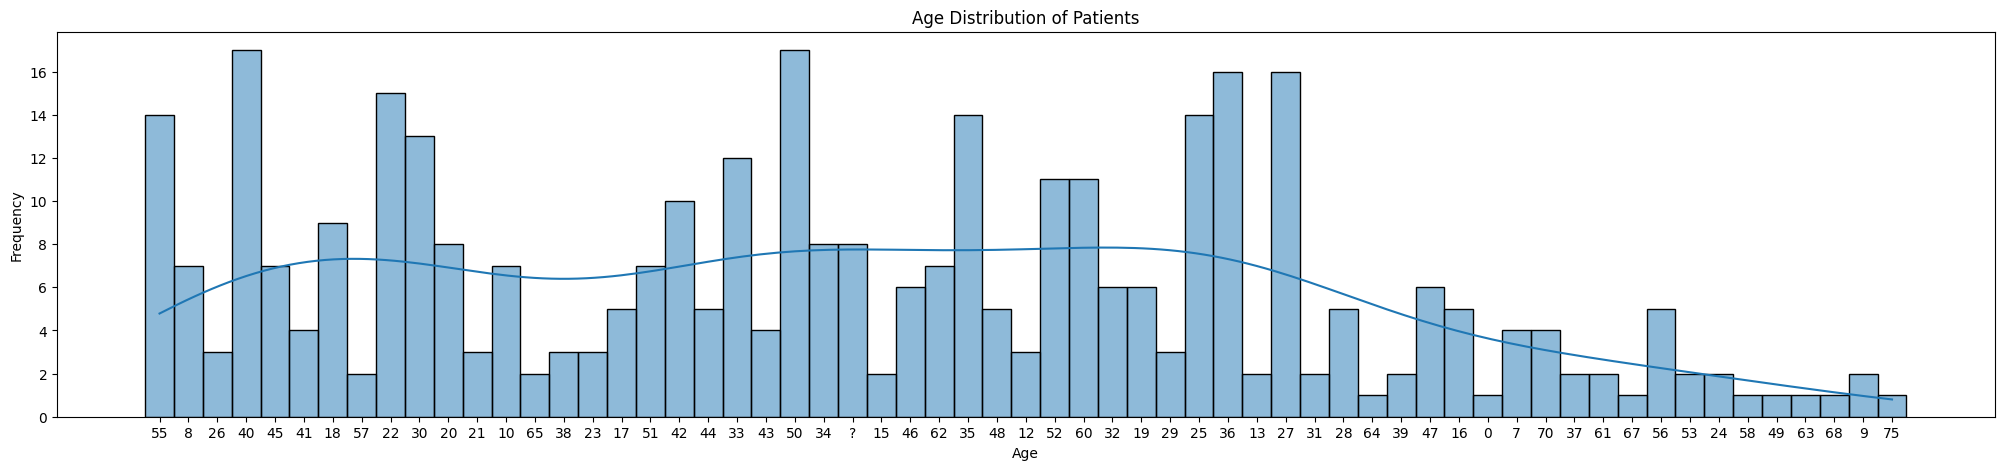

In [14]:
plt.figure(figsize=(25,5))
sns.histplot(data['Age'], kde=True)
plt.title('Age Distribution of Patients')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

In [15]:
#most patients fall within the adult age group

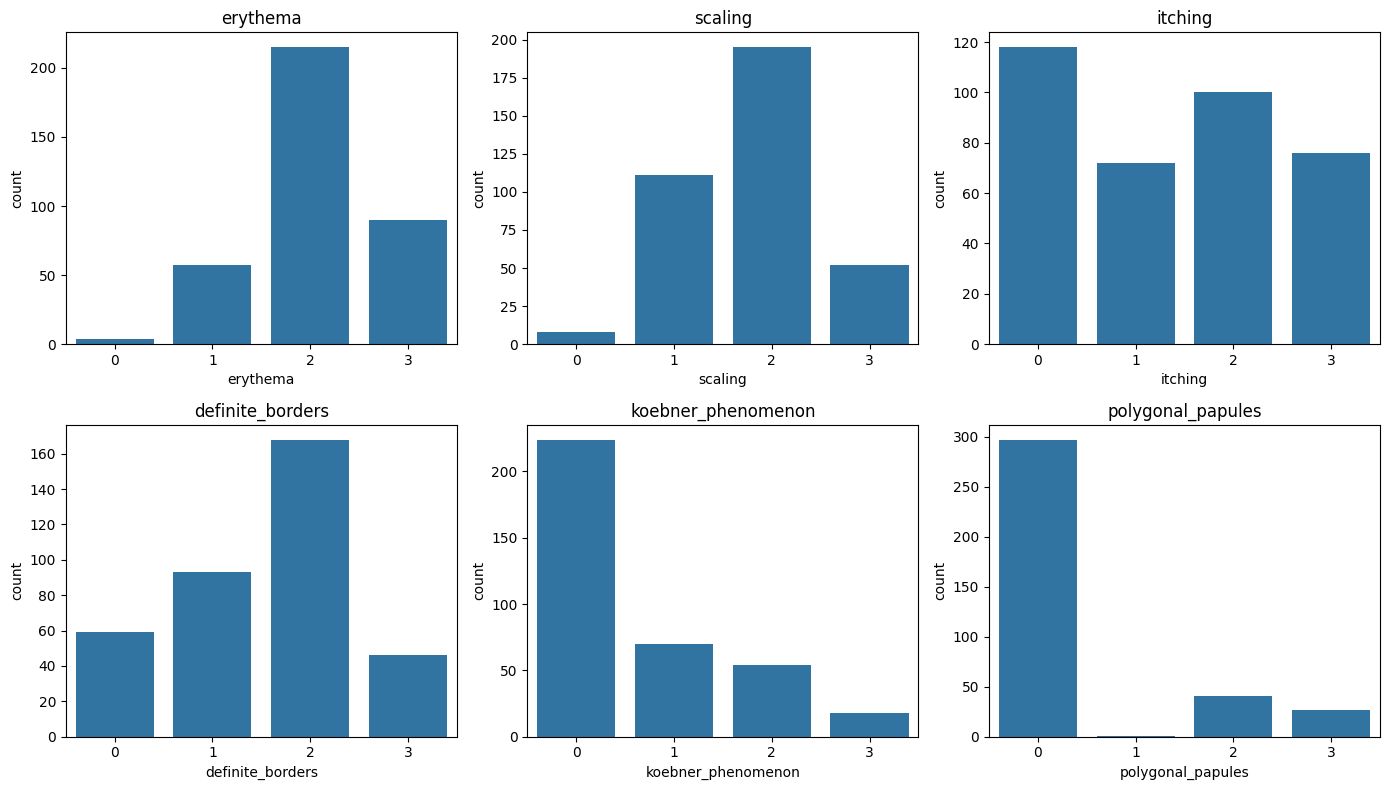

In [16]:
clinical_features = [
    'erythema','scaling','itching','definite_borders',
    'koebner_phenomenon','polygonal_papules'
]

plt.figure(figsize=(14,8))
for i,col in enumerate(clinical_features,1):
    plt.subplot(2,3,i)
    sns.countplot(x=data[col])
    plt.title(col)
plt.tight_layout()
plt.show()

In [17]:
#Clinical features show higher frequency at severity levels 1 and 2  

# Data Preprocessing

In [18]:
data.isnull().sum()

erythema                                    0
scaling                                     0
definite_borders                            0
itching                                     0
koebner_phenomenon                          0
polygonal_papules                           0
follicular_papules                          0
oral_mucosal_involvement                    0
knee_and_elbow_involvement                  0
scalp_involvement                           0
family_history                              0
melanin_incontinence                        0
eosinophils_in_the_infiltrate               0
PNL_infiltrate                              0
fibrosis_of_the_papillary_dermis            0
exocytosis                                  0
acanthosis                                  0
hyperkeratosis                              0
parakeratosis                               0
clubbing_of_the_rete_ridges                 0
elongation_of_the_rete_ridges               0
thinning_of_the_suprapapillary_epi

In [19]:
#there are no null values

In [20]:
data.duplicated().sum()

0

In [21]:
#there are no duplicate records

In [22]:
data.rename(columns={'class':'target'},inplace=True)

In [23]:
#The column `class` is renamed to `target` to avoid Python keyword issues.

In [24]:
data.Age.unique()

array(['55', '8', '26', '40', '45', '41', '18', '57', '22', '30', '20',
       '21', '10', '65', '38', '23', '17', '51', '42', '44', '33', '43',
       '50', '34', '?', '15', '46', '62', '35', '48', '12', '52', '60',
       '32', '19', '29', '25', '36', '13', '27', '31', '28', '64', '39',
       '47', '16', '0', '7', '70', '37', '61', '67', '56', '53', '24',
       '58', '49', '63', '68', '9', '75'], dtype=object)

In [25]:
#this helps identify non-numeric values such as '?' or strings and here is '?' present in Age column.

In [26]:
data['Age']=pd.to_numeric(data['Age'],errors='coerce')

In [27]:
#Non-numeric values are converted to NaN using coercion.

In [28]:
data.isnull().sum()

erythema                                    0
scaling                                     0
definite_borders                            0
itching                                     0
koebner_phenomenon                          0
polygonal_papules                           0
follicular_papules                          0
oral_mucosal_involvement                    0
knee_and_elbow_involvement                  0
scalp_involvement                           0
family_history                              0
melanin_incontinence                        0
eosinophils_in_the_infiltrate               0
PNL_infiltrate                              0
fibrosis_of_the_papillary_dermis            0
exocytosis                                  0
acanthosis                                  0
hyperkeratosis                              0
parakeratosis                               0
clubbing_of_the_rete_ridges                 0
elongation_of_the_rete_ridges               0
thinning_of_the_suprapapillary_epi

In [29]:
#there are 8 null values in Age.

In [30]:
data['Age'].fillna(data['Age'].median(),inplace=True)

In [31]:
data.isnull().sum()

erythema                                    0
scaling                                     0
definite_borders                            0
itching                                     0
koebner_phenomenon                          0
polygonal_papules                           0
follicular_papules                          0
oral_mucosal_involvement                    0
knee_and_elbow_involvement                  0
scalp_involvement                           0
family_history                              0
melanin_incontinence                        0
eosinophils_in_the_infiltrate               0
PNL_infiltrate                              0
fibrosis_of_the_papillary_dermis            0
exocytosis                                  0
acanthosis                                  0
hyperkeratosis                              0
parakeratosis                               0
clubbing_of_the_rete_ridges                 0
elongation_of_the_rete_ridges               0
thinning_of_the_suprapapillary_epi

In [32]:
#null values handled correctly with median

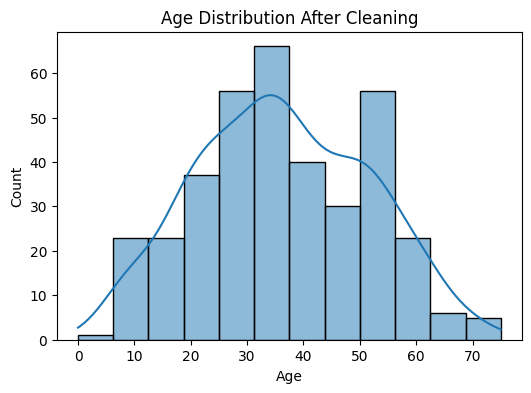

In [33]:
plt.figure(figsize=(6,4))
sns.histplot(data['Age'], kde=True)
plt.title('Age Distribution After Cleaning')
plt.show()

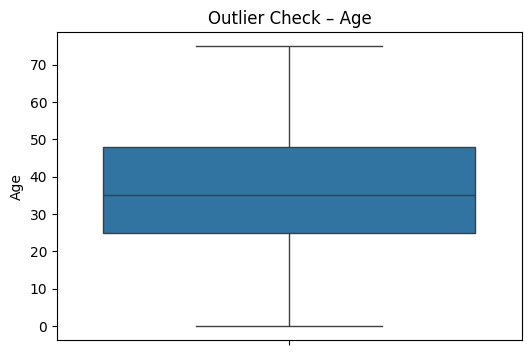

In [34]:
plt.figure(figsize=(6,4))
sns.boxplot(y=data['Age'])
plt.title('Outlier Check – Age')
plt.show()

In [35]:
#No extreme values observed

# Feature Selection

In [36]:
from sklearn.preprocessing import StandardScaler

sc=StandardScaler()
data['Age_scaled']=sc.fit_transform(data[['Age']])

In [38]:
data.drop('Age',axis=1,inplace=True)

In [ ]:
#The original Age column is removed and only the scaled version is kept for model training.

In [39]:
data.head()

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,target,Age_scaled
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,2,1.237583
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,1,-1.867565
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,3,-0.678360
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,1,0.246578
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,3,0.576913


In [40]:
X=data.drop('target',axis=1)
y=data['target']

In [41]:
#X contains all independent features  
#y contains disease class labels

In [42]:
y.value_counts(normalize=True) * 100

target
1    30.601093
3    19.672131
2    16.666667
5    14.207650
4    13.387978
6     5.464481
Name: proportion, dtype: float64

Although the dataset shows class imbalance, the imbalance is moderate.
Tree-based models can handle this effectively.
Therefore, no resampling technique was applied to avoid data distortion.

In [43]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test =train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [46]:
#Stratified sampling was applied to preserve the original class distribution in both sets, ensuring fair model evaluation.

In [45]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((292, 34), (74, 34), (292,), (74,))

# Model Building and Evaluation

In [44]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [47]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "SVM": SVC(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}


In [48]:
results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    results[name] = acc

    print(f"\n{name}")
    print("Accuracy:", acc)
    print(classification_report(y_test, y_pred))



Logistic Regression
Accuracy: 0.9594594594594594
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       0.91      0.83      0.87        12
           3       1.00      1.00      1.00        15
           4       0.82      0.90      0.86        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.96        74
   macro avg       0.95      0.96      0.95        74
weighted avg       0.96      0.96      0.96        74


KNN
Accuracy: 0.9324324324324325
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       0.89      0.67      0.76        12
           3       1.00      1.00      1.00        15
           4       0.69      0.90      0.78        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00     

In [49]:
import pandas as pd

results_df = pd.DataFrame.from_dict(results, orient='index', columns=['Accuracy'])
results_df.sort_values(by='Accuracy', ascending=False)


,Accuracy
SVM,0.972973
Logistic Regression,0.959459
Random Forest,0.959459
KNN,0.932432
Decision Tree,0.932432


### Ann model

In [50]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import StandardScaler


In [51]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [52]:
#one-hot encoding
y_train_cat = to_categorical(y_train - 1)
y_test_cat = to_categorical(y_test - 1)

In [55]:
ann_model = Sequential()

ann_model.add(Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)))
ann_model.add(Dropout(0.3))

ann_model.add(Dense(32, activation='relu'))
ann_model.add(Dropout(0.3))

ann_model.add(Dense(6, activation='softmax'))


In [56]:
ann_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


In [57]:
history = ann_model.fit(
    X_train_scaled,
    y_train_cat,
    epochs=50,
    batch_size=16,
    validation_split=0.1,
    verbose=1
)


Epoch 1/50
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 51ms/step - accuracy: 0.3282 - loss: 1.6720 - val_accuracy: 0.6667 - val_loss: 1.1013
Epoch 2/50
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5802 - loss: 1.1879 - val_accuracy: 0.7000 - val_loss: 0.8064
Epoch 3/50
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6679 - loss: 0.9968 - val_accuracy: 0.8333 - val_loss: 0.6281
Epoch 4/50
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7137 - loss: 0.7913 - val_accuracy: 0.9000 - val_loss: 0.5118
Epoch 5/50
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7634 - loss: 0.6663 - val_accuracy: 0.9667 - val_loss: 0.4169
Epoch 6/50
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8130 - loss: 0.6219 - val_accuracy: 0.9667 - val_loss: 0.3337
Epoch 7/50
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8550 - loss: 0.5076 - val_accuracy: 0.9667 - val_loss: 0.2647
Epoch 8/50
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8817 - loss: 0.4285 - val_accuracy: 0.9667 - v

In [59]:
ann_loss, ann_accuracy = ann_model.evaluate(X_test_scaled, y_test_cat)
print("ANN Test Accuracy:", ann_accuracy)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9595 - loss: 0.1287
ANN Test Accuracy: 0.9594594836235046


# Hyperparameter tuning

Since the baseline models already achieved high accuracy and stable class-wise performance, extensive hyperparameter tuning was not applied
to all models.
To demonstrate optimization techniques without overfitting, we will perform hyperparameter tuning only on the best-performing model (SVM).

In [62]:
from sklearn.model_selection import GridSearchCV

# Parameter grid
param_grid = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

# GridSearch
svm_grid = GridSearchCV(
    estimator=SVC(),
    param_grid=param_grid,
    scoring='f1_weighted',
    cv=5,
    n_jobs=-1
)

# Fit on training data (scaled)
svm_grid.fit(X_train, y_train)

# Best parameters
svm_grid.best_params_


{'C': 10, 'gamma': 'scale', 'kernel': 'linear'}

In [63]:
best_svm = svm_grid.best_estimator_

best_svm

SVC(C=10, kernel='linear')

In [64]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Predictions
y_pred_svm_tuned = best_svm.predict(X_test)

# Accuracy
svm_tuned_accuracy = accuracy_score(y_test, y_pred_svm_tuned)
print("Tuned SVM Accuracy:", svm_tuned_accuracy)

# Classification Report
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_svm_tuned))


Tuned SVM Accuracy: 0.972972972972973

Classification Report:

              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       1.00      0.83      0.91        12
           3       1.00      1.00      1.00        15
           4       0.83      1.00      0.91        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.97        74
   macro avg       0.97      0.97      0.97        74
weighted avg       0.98      0.97      0.97        74



In [65]:
#hyperparameter tuning improved class-wise consistency without overfitting, confirming SVM as the most reliable model for production.

# Model Comparison Report

#### Objective
The objective of this comparison is to evaluate multiple machine learning and deep learning models for predicting different classes of erythemato-squamous skin diseases and to identify the most reliable model for clinical use.

#### Models Evaluated
The following models were trained and evaluated using accuracy, precision, recall, and F1-score:

1.Logistic Regression

2.K-Nearest Neighbors (KNN)

3.Support Vector Machine (SVM)

4.Decision Tree

5.Random Forest

6.Artificial Neural Network (ANN)

7.Tuned Support Vector Machine (SVM with GridSearchCV)


#### Model Performances
| Model               | Accuracy     | Macro F1   | 
| ------------------- | ------------ | ---------- | 
| Logistic Regression | 95.95%       | 0.95       | 
| KNN                 | 93.24%       | 0.92       | 
| Decision Tree       | 93.24%       | 0.89       | 
| Random Forest       | 95.95%       | 0.95       | 
| ANN                 | 95.95%       | 0.96       | 
| **SVM (Baseline)**  | **97.30%**   | **0.97**   | 
| **SVM (Tuned)**     | **97.30%**   | **0.97**   |


- All models achieved high accuracy (>93%), indicating strong predictive capability.

- SVM consistently outperformed other models, achieving the highest accuracy and balanced precision-recall across all classes.

- Decision Tree and KNN showed weaker performance on minority classes, making them less suitable for clinical deployment.

- Random Forest and ANN provided competitive results but added complexity without significant performance gain over SVM.

- Hyperparameter tuning of SVM improved class-wise consistency, especially recall for clinically sensitive classes.

### Final Model Selection
#### Selected Model: Tuned SVM

Based on comparative evaluation, the tuned Support Vector Machine (SVM) was selected as the final production model. 
It achieved the highestaccuracy along with balanced precision, recall, and F1-score across all
skin disease classes, making it the most reliable and clinically appropriate model for early skin disease prediction.
In healthcare, recall is more important than accuracy, as missing a disease can lead to delayed treatment.
The tuned SVM achieved high recall for all disease classes, making it safer for early diagnosis support.
Balanced macro and weighted F1-scores confirm that the model does not favor dominant classes.

### Conclusion

The model comparison demonstrates that while multiple algorithms perform well, SVM offers the best trade-off between accuracy, robustness, and generalization. Its stable performance across all disease classes makes it the optimal choice for real-world clinical decision support systems.

<Figure size 800x600 with 0 Axes>

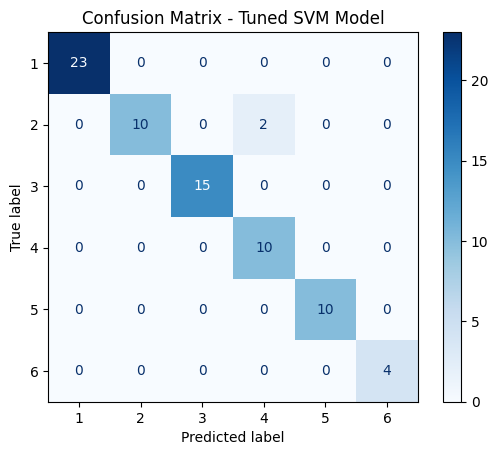

In [66]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred_svm_tuned)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_svm.classes_
)

plt.figure(figsize=(8,6))
disp.plot(cmap='Blues', values_format='d')
plt.title("Confusion Matrix - Tuned SVM Model")
plt.show()


In [67]:
#The confusion matrix shows that the tuned SVM model correctly classifies the majority of skin disease cases across all six classes.

# Challenges Faced and Solutions

1. Most skin diseases in the dataset share similar clinical symptoms such as erythema and scaling, leading to overlapping feature patterns across different classes.

Solution:
Combined clinical and histopathological features for model training.
Used Support Vector Machine (SVM) to handle non-linear decision boundaries.

2. The dataset contains six skin disease classes, increasing model complexity and the chance of misclassification.

Solution:
Applied multi-class classification algorithms (SVM, Random Forest, ANN).
Evaluated performance using macro and weighted F1-scores.

3. Some disease classes had fewer samples, which could bias model predictions.

Solution:
Used stratified train-test split.
Focused on recall and F1-score during evaluation instead of accuracy alone.

4. The Age column was stored as an object data type, preventing direct numerical processing.

Solution:
Converted the Age column to numeric.
Applied feature scaling using StandardScaler.

5. The dataset contains only 366 records, increasing the risk of overfitting.

Solution:
Used cross-validation during hyperparameter tuning.
Performed selective tuning only on the best model (SVM).

6. Accuracy alone was insufficient due to class imbalance and healthcare relevance.

Solution:
Used precision, recall, F1-score, and confusion matrix.


# Future Scope

1. Inclusion of Image-Based Diagnosis

The current system relies on clinical and histopathological attributes. In the future, dermoscopic and skin lesion images can be integrated using deep learning (CNNs) to improve diagnostic accuracy and automation.

2. Real-Time Clinical Decision Support

The model can be deployed as a web or mobile application to assist dermatologists in real-time diagnosis, especially in rural or resource-limited healthcare settings.

3. Larger and More Diverse Dataset

Expanding the dataset with more patient records and diverse age groups and ethnicities would improve model generalization and reliability.

4. Explainable AI Integration

Future work can include explainable AI techniques to interpret model predictions and help doctors understand key contributing features.


# Suggestions to Doctors for Early Identification of Skin Diseases

1. Use Clinical + Histopathological Features Together

Doctors should consider both visible clinical symptoms (erythema, scaling, itching) and histopathological findings to improve diagnostic accuracy, especially for diseases with overlapping symptoms.

2. Focus on Early Symptom Patterns

Early-stage skin diseases may not show complete characteristics. 
Doctors are advised to:
Monitor subtle symptom combinations
Re-evaluate patients over time
Use predictive tools for early warning

3. Utilize AI-Based Decision Support Systems

Machine learning models like SVM-based prediction systems can assist doctors by:
Providing preliminary diagnosis
Reducing diagnostic time
Supporting less-experienced clinicians
(AI should support, not replace, clinical judgment.)

4. Prioritize Recall Over Accuracy

In medical diagnosis:
Missing a disease is more harmful than over-diagnosis,Doctors should prefer systems with high recall

5. Regular Model Updates

Doctors using AI tools should ensure:
Models are updated with recent patient data,Predictions reflect current clinical trends